# 05 — Sellers: pontualidade de postagem e rankings de atraso

**Objetivo:** diagnosticar, retrospectivamente, quais sellers concentram as postagens atrasadas.

**Base:** tabela `pedido_seller` (1 linha por `order_id` + `seller_id`). Para cada combinação, o prazo é a **menor** `shipping_limit_date` dos itens daquele seller no pedido, comparada com `order_delivered_carrier_date` (no prazo se `<=`).

> ⚠️ Um pedido com itens de 2 sellers aparece 2 vezes nesta tabela. As contagens aqui são **pedido–seller**, não pedidos únicos do marketplace; o KPI3 oficial (por pedido) está no notebook 03.

> ⚠️ Limitação do dataset: existe **uma única** data de postagem por pedido. Em pedidos com vários sellers, essa data é atribuída a todos eles.

Os rankings são diagnóstico histórico (2017–2018), **não** alertas atuais.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import olist_utils as U

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)
sns.set_theme(style="whitegrid")

ps = U.load_processed("pedido_seller")
itens = U.load_processed("itens")
print(ps.shape, "| pedidos únicos:", ps["order_id"].nunique(), "| sellers:", ps["seller_id"].nunique())
print("Pedidos com mais de um seller:", int((ps.groupby("order_id").size() > 1).sum()))

(75845, 22) | pedidos únicos: 74781 | sellers: 2810
Pedidos com mais de um seller: 1012


## 1. KPIs por seller (por período e consolidado)

In [2]:
def kpi_seller(df, by):
    d = df.assign(_eleg=df["postagem_elegivel"].astype(int),
                  _atras=df["postagem_atrasada"].astype("boolean").fillna(False).astype(int),
                  _aval=df["tem_avaliacao"].astype(int),
                  _ruim=df["avaliacao_ruim"].astype("boolean").fillna(False).astype(int),
                  _ent_ok=df["entrega_atrasada"].notna().astype(int),
                  _ent_atr=df["entrega_atrasada"].astype("boolean").fillna(False).astype(int))
    out = d.groupby(by, dropna=False).agg(
        seller_state=("seller_state", "first"),
        seller_regiao=("seller_regiao", "first"),
        pedido_seller_total=("order_id", "size"),
        pedido_seller_elegiveis_postagem=("_eleg", "sum"),
        pedido_seller_postagem_atrasada=("_atras", "sum"),
        pedido_seller_com_avaliacao=("_aval", "sum"),
        pedido_seller_avaliacao_ruim=("_ruim", "sum"),
        pedido_seller_entrega_avaliavel=("_ent_ok", "sum"),
        pedido_seller_entrega_atrasada=("_ent_atr", "sum"),
        itens=("qtd_itens", "sum"),
        soma_preco=("soma_preco", "sum"),
        soma_frete=("soma_frete", "sum"),
    ).reset_index()
    out["pedido_seller_postagem_no_prazo"] = out["pedido_seller_elegiveis_postagem"] - out["pedido_seller_postagem_atrasada"]
    out["pct_postagem_atrasada"] = U.pct(out["pedido_seller_postagem_atrasada"], out["pedido_seller_elegiveis_postagem"])
    out["pct_postagem_no_prazo"] = U.pct(out["pedido_seller_postagem_no_prazo"], out["pedido_seller_elegiveis_postagem"])
    out["pct_avaliacao_ruim"] = U.pct(out["pedido_seller_avaliacao_ruim"], out["pedido_seller_com_avaliacao"])
    out["pct_entrega_atrasada"] = U.pct(out["pedido_seller_entrega_atrasada"], out["pedido_seller_entrega_avaliavel"])
    out["pct_frete_sobre_produto"] = U.pct(out["soma_frete"], out["soma_preco"])
    out = U.flag_amostra(out, "pedido_seller_elegiveis_postagem")
    out["granularidade"] = "seller" + ("_periodo" if "ano_original" in by else "_consolidado")
    return out

seller_periodo = kpi_seller(ps, ["seller_id", "ano_original", "periodo_comparativo"])
seller_total = kpi_seller(ps, ["seller_id"])
seller_total["ano_original"] = np.nan
seller_total["periodo_comparativo"] = "consolidado (jan-ago/2017 + jan-ago/2018)"
kpi_seller_df = pd.concat([seller_periodo, seller_total], ignore_index=True)

# sanity: soma das linhas por seller == linhas pedido-seller
assert seller_total["pedido_seller_total"].sum() == len(ps)
print("Sellers com amostra pequena (<30 elegíveis, consolidado):", int(seller_total["amostra_pequena"].sum()),
      "de", len(seller_total))

Sellers com amostra pequena (<30 elegíveis, consolidado): 2286 de 2810


## 2. Concentração dos atrasos
Quão concentrado está o problema? Se poucos sellers respondem pela maior parte das postagens atrasadas, uma ação focada em sellers é mais viável.

In [3]:
st = seller_total.sort_values("pedido_seller_postagem_atrasada", ascending=False).reset_index(drop=True)
total_atrasos = st["pedido_seller_postagem_atrasada"].sum()
st["pct_acumulado_atrasos"] = st["pedido_seller_postagem_atrasada"].cumsum() / total_atrasos * 100
sellers_com_atraso = int((st["pedido_seller_postagem_atrasada"] > 0).sum())
conc = pd.DataFrame({
    "top_n_sellers": [10, 50, 100, 200],
    "pct_das_postagens_atrasadas": [st.loc[:n - 1, "pedido_seller_postagem_atrasada"].sum() / total_atrasos * 100
                                    for n in [10, 50, 100, 200]],
    "pct_do_volume_pedido_seller": [st.loc[:n - 1, "pedido_seller_total"].sum() / len(ps) * 100
                                    for n in [10, 50, 100, 200]],
}).round(2)
print(f"Postagens atrasadas (pedido-seller): {total_atrasos} | sellers com ao menos 1 atraso: {sellers_com_atraso} de {len(st)}")
conc

Postagens atrasadas (pedido-seller): 6451 | sellers com ao menos 1 atraso: 1194 de 2810


,top_n_sellers,pct_das_postagens_atrasadas,pct_do_volume_pedido_seller
0,10,16.87,8.10
1,50,39.87,23.88
2,100,53.17,31.17
3,200,67.77,47.40


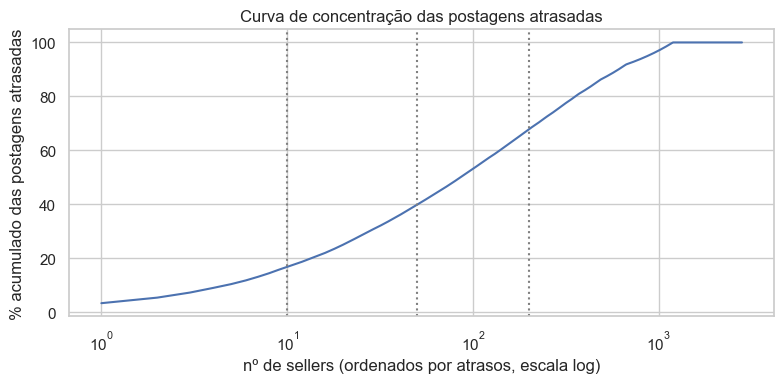

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(st) + 1), st["pct_acumulado_atrasos"])
ax.set_xscale("log"); ax.set_xlabel("nº de sellers (ordenados por atrasos, escala log)")
ax.set_ylabel("% acumulado das postagens atrasadas"); ax.set_title("Curva de concentração das postagens atrasadas")
for n in [10, 50, 200]:
    ax.axvline(n, ls=":", c="gray")
fig.tight_layout(); fig.savefig(U.FIG_DIR / "05_concentracao_atrasos_sellers.png", dpi=120)

## 3. Top 50 sellers com mais postagens atrasadas
Ordenação por **número absoluto** de postagens atrasadas (consolidado dos dois recortes), como pede a proposta; a taxa e o volume aparecem lado a lado.

In [5]:
top50 = st.head(50).copy()
top50.insert(0, "rank", range(1, len(top50) + 1))
top50 = top50.drop(columns=["ano_original"])
top50["granularidade"] = "seller_consolidado_top50"
top50[["rank", "seller_id", "seller_state", "pedido_seller_elegiveis_postagem", "pedido_seller_postagem_atrasada",
       "pct_postagem_atrasada", "pct_avaliacao_ruim", "pct_entrega_atrasada", "amostra_pequena"]].head(20).round(2)

,rank,seller_id,seller_state,pedido_seller_elegiveis_postagem,pedido_seller_postagem_atrasada,pct_postagem_atrasada,pct_avaliacao_ruim,pct_entrega_atrasada,amostra_pequena
0,1,7c67e1448b00f6e969d365cea6b010ab,SP,793,221,27.87,23.63,6.81,False
1,2,1f50f920176fa81dab994f9023523100,SP,811,133,16.40,12.48,7.03,False
2,3,06a2c3af7b3aee5d69171b0e14f0ee87,MA,389,121,31.11,16.10,19.02,False
3,4,88460e8ebdecbfecb5f9601833981930,PR,231,111,48.05,29.57,17.32,False
4,5,1025f0e2d44d7041d6cf58b6550e0bfa,SP,708,91,12.85,16.24,5.93,False
5,6,4a3ca9315b744ce9f8e9374361493884,SP,1299,89,6.85,17.03,7.47,False
6,7,92eb0f42c21942b6552362b9b114707d,SP,327,88,26.91,14.15,4.89,False
7,8,7d13fca15225358621be4086e1eb0964,SP,558,83,14.87,17.12,11.47,False
8,9,53e4c6e0f4312d4d2107a8c9cddf45cd,SP,352,82,23.30,12.00,4.26,False
9,10,3d871de0142ce09b7081e2b9d1733cb1,SP,679,69,10.16,8.63,4.12,False


In [6]:
# Top 50 também por período (útil para o dashboard filtrar)
top50_periodo = (seller_periodo.sort_values(["ano_original", "pedido_seller_postagem_atrasada"], ascending=[True, False])
                 .groupby("ano_original").head(50).copy())
top50_periodo["rank"] = top50_periodo.groupby("ano_original").cumcount() + 1
top50_periodo["granularidade"] = "seller_periodo_top50"
top50_export = pd.concat([top50.assign(ano_original=np.nan), top50_periodo], ignore_index=True)
top50_export.groupby("periodo_comparativo")["rank"].max()

periodo_comparativo
2024 (proxy jan-ago/2017)                    50
2025 (proxy jan-ago/2018)                    50
consolidado (jan-ago/2017 + jan-ago/2018)    50
Name: rank, dtype: int64

## 4. Ranking semanal (top 50 por semana)
Semana = semana (segunda a domingo) da **data limite de postagem** do seller no pedido. Isso reproduz a ideia operacional da proposta ("toda semana, quem mais atrasou"), aplicada aos dados históricos.

In [7]:
sem = (ps[ps["postagem_elegivel"]]
       .assign(_atras=lambda d: d["postagem_atrasada"].astype("boolean").astype(int))
       .groupby(["semana_prazo_postagem", "seller_id"])
       .agg(ano_original=("ano_original", "first"), periodo_comparativo=("periodo_comparativo", "first"),
            seller_state=("seller_state", "first"),
            pedido_seller_elegiveis_postagem=("_atras", "size"), pedido_seller_postagem_atrasada=("_atras", "sum"))
       .reset_index())
sem = sem[sem["pedido_seller_postagem_atrasada"] > 0]
sem["pct_postagem_atrasada"] = U.pct(sem["pedido_seller_postagem_atrasada"], sem["pedido_seller_elegiveis_postagem"])
sem = sem.sort_values(["semana_prazo_postagem", "pedido_seller_postagem_atrasada", "pct_postagem_atrasada"],
                      ascending=[True, False, False])
sem["rank_semana"] = sem.groupby("semana_prazo_postagem").cumcount() + 1
ranking_semanal = sem[sem["rank_semana"] <= 50].copy()
ranking_semanal["granularidade"] = "semana_seller (top 50 por semana)"
print("Semanas:", ranking_semanal["semana_prazo_postagem"].nunique(), "| linhas:", len(ranking_semanal))
# Observação: a semana do prazo pode cair fora de jan-ago (ex.: compra em 31/08 com prazo em setembro).
ranking_semanal.head(10)

Semanas: 72 | linhas: 2934


,semana_prazo_postagem,seller_id,ano_original,periodo_comparativo,seller_state,pedido_seller_elegiveis_postagem,pedido_seller_postagem_atrasada,pct_postagem_atrasada,rank_semana,granularidade
6,2017-01-09,48efc9d94a9834137efd9ea76b065a38,2017,2024 (proxy jan-ago/2017),PR,31,28,90.322581,1,semana_seller (top 50 por semana)
0,2017-01-09,054694fa03fe82cec4b7551487331d74,2017,2024 (proxy jan-ago/2017),SP,1,1,100.000000,2,semana_seller (top 50 por semana)
3,2017-01-09,1b8b75e227c9a9c100d0c210fb6176ce,2017,2024 (proxy jan-ago/2017),SP,1,1,100.000000,3,semana_seller (top 50 por semana)
8,2017-01-09,4d600e08ecbe08258c79e536c5a42fee,2017,2024 (proxy jan-ago/2017),PR,1,1,100.000000,4,semana_seller (top 50 por semana)
18,2017-01-09,dbb9b48c841a0e39e21f98e1a6b2ec3e,2017,2024 (proxy jan-ago/2017),SP,1,1,100.000000,5,semana_seller (top 50 por semana)
10,2017-01-09,80e6699fe29150b372a0c8a1ebf7dcc8,2017,2024 (proxy jan-ago/2017),PR,3,1,33.333333,6,semana_seller (top 50 por semana)
16,2017-01-09,c9a06ece156bb057372c68718ec8909b,2017,2024 (proxy jan-ago/2017),DF,4,1,25.000000,7,semana_seller (top 50 por semana)
49,2017-01-16,70a12e78e608ac31179aea7f8422044b,2017,2024 (proxy jan-ago/2017),SP,3,3,100.000000,1,semana_seller (top 50 por semana)
37,2017-01-16,4a3ca9315b744ce9f8e9374361493884,2017,2024 (proxy jan-ago/2017),SP,8,3,37.500000,2,semana_seller (top 50 por semana)
55,2017-01-16,834f8533b2ecb6598dd004ff3de7203a,2017,2024 (proxy jan-ago/2017),SP,2,2,100.000000,3,semana_seller (top 50 por semana)


In [8]:
# Recorrência: sellers que aparecem com frequência no ranking semanal
recorr = ranking_semanal.groupby("seller_id").agg(semanas_no_top50=("rank_semana", "size"),
                                                  atrasos=("pedido_seller_postagem_atrasada", "sum"))
recorr.sort_values("semanas_no_top50", ascending=False).head(10)

,semanas_no_top50,atrasos
seller_id,,
7c67e1448b00f6e969d365cea6b010ab,36,215
4a3ca9315b744ce9f8e9374361493884,29,81
53e4c6e0f4312d4d2107a8c9cddf45cd,26,77
92eb0f42c21942b6552362b9b114707d,25,81
b2ba3715d723d245138f291a6fe42594,20,44
70a12e78e608ac31179aea7f8422044b,20,43
4c2b230173bb36f9b240f2b8ac11786e,19,48
1f50f920176fa81dab994f9023523100,19,129
213b25e6f54661939f11710a6fddb871,18,47


## 5. Atraso de postagem por UF do seller
Ajuda a separar problema de seller/origem de problema logístico de destino.

In [9]:
d = ps.assign(_eleg=ps["postagem_elegivel"].astype(int),
              _atras=ps["postagem_atrasada"].astype("boolean").fillna(False).astype(int))
uf_seller = d.groupby(["periodo_comparativo", "seller_state"]).agg(
    pedido_seller_elegiveis=("_eleg", "sum"), pedido_seller_atrasadas=("_atras", "sum"),
    sellers=("seller_id", "nunique")).reset_index()
uf_seller["pct_postagem_atrasada"] = U.pct(uf_seller["pedido_seller_atrasadas"], uf_seller["pedido_seller_elegiveis"])
uf_seller = U.flag_amostra(uf_seller, "pedido_seller_elegiveis")
uf_seller[uf_seller["periodo_comparativo"].str.startswith("2025")].sort_values(
    "pedido_seller_atrasadas", ascending=False).head(10).round(2)

,periodo_comparativo,seller_state,pedido_seller_elegiveis,pedido_seller_atrasadas,sellers,pct_postagem_atrasada,amostra_pequena
39,2025 (proxy jan-ago/2018),SP,38331,3212,1381,8.38,False
32,2025 (proxy jan-ago/2018),PR,4469,445,261,9.96,False
25,2025 (proxy jan-ago/2018),MG,3609,218,179,6.04,False
33,2025 (proxy jan-ago/2018),RJ,2519,171,129,6.79,False
37,2025 (proxy jan-ago/2018),SC,1772,151,144,8.52,False
24,2025 (proxy jan-ago/2018),MA,389,121,1,31.11,False
36,2025 (proxy jan-ago/2018),RS,1000,80,98,8.00,False
21,2025 (proxy jan-ago/2018),DF,416,40,25,9.62,False
23,2025 (proxy jan-ago/2018),GO,252,18,34,7.14,False
27,2025 (proxy jan-ago/2018),MT,73,16,4,21.92,False


## 6. Exportação

In [10]:
U.export_csv(kpi_seller_df, "kpi_seller")
U.export_csv(top50_export, "top_50_sellers_atraso")
U.export_csv(ranking_semanal, "ranking_semanal_sellers_atraso")
U.export_csv(uf_seller.assign(granularidade="periodo_uf_seller"), "kpi_uf_seller_postagem")
U.save_processed(conc, "concentracao_atrasos")
print("Exportados: kpi_seller.csv, top_50_sellers_atraso.csv, ranking_semanal_sellers_atraso.csv, kpi_uf_seller_postagem.csv")

Exportados: kpi_seller.csv, top_50_sellers_atraso.csv, ranking_semanal_sellers_atraso.csv, kpi_uf_seller_postagem.csv
